# 고단백 제품은 효율적인 단백질 공급원인가?

**팀원**: 권민영 · {A_NAME}
숭실대학교 AI와 데이터 분석 실습 · 데이터 버전 `v001` (2026-11-17)

편의점과 마트에는 "프로틴", "고단백", "단백질 20g"을 앞세운 바·요거트·우유 음료가 많습니다. 운동하는 사람뿐 아니라 끼니를 가볍게 해결하려는 사람도 이런 표시를 보고 제품을 고릅니다. 그런데 포장 앞면의 강조 문구는 **파는 쪽의 메시지**입니다. 강조 제품이 같은 종류의 일반 제품보다 같은 열량으로 단백질을 정말 더 많이 주는지, 그 대가로 당류·나트륨·포화지방을 더 먹게 되지는 않는지는 문구만 보고는 알 수 없습니다.

이 튜토리얼은 공공 영양성분 데이터와 직접 확인한 포장 정보를 이용해 이 질문에 답합니다. 데이터를 고르는 규칙부터 수작업 라벨링, 정제, 탐색, 가설검정, 머신러닝, 사례 비교까지 전 과정을 코드와 함께 보여 줍니다. 모든 코드는 저장소에 들어 있는 가공 데이터로 다시 실행할 수 있습니다.

[GitHub 저장소](https://github.com/kmy040306/kmy040306.github.io) · [식약처 가공식품 영양성분 데이터](https://www.data.go.kr/data/15100066/standard.do) · [식약처 영양표시 가이드라인](https://www.mfds.go.kr/brd/m_1060/view.do?seq=15805)

## 1. 연구 질문과 가설

| 구분 | 질문 | 검증 방법 |
|---|---|---|
| 주가설 | 같은 식품군에서 단백질 강조 시리즈의 평균 단백질 효율이 일반 시리즈보다 높은가? | 양측 Welch t 검정, 평균 차이와 95% 신뢰구간 |
| 부가설 1~4 | 두 집단의 당류·나트륨·포화지방·열량 평균은 다른가? | 같은 식품군 안에서 각각 Welch t 검정 |
| 확장 가설 | 효율 차이의 크기가 바·요거트·음료마다 다른가? | 효율 ~ 강조 여부 × 식품군 회귀의 상호작용 검정 |
| 머신러닝 | 단백질 수치를 보지 않고 당류·나트륨·포화지방만으로 강조 제품을 구별할 수 있는가? | 로지스틱 회귀·결정트리, 층화 5겹 교차검증 |
| 사례 비교 | 효율이 가장 좋은 강조 제품은 닭가슴살·달걀·두부와 비교하면 어떤가? | 단백질 20g당 함께 먹는 성분 계산 |

주가설과 부가설의 15개 검정(3개 식품군 × 5개 지표)은 Holm 방식으로 함께 보정합니다. 가격, 흡수율, "건강에 좋은가" 같은 종합 판단은 데이터로 확인할 수 없어 다루지 않습니다.

### 무엇을 비교하는가: 단백질 효율

같은 기준량(100g 또는 100mL)의 단백질 $P$(g)와 열량 $E$(kcal)로

$$\text{단백질 효율} = \frac{P}{E} \times 100 \quad (\text{g}/100\text{kcal})$$

를 계산합니다. "100kcal를 먹으면 단백질을 몇 g 얻는가"라는 뜻입니다. 무게 대신 열량을 분모로 쓰는 이유는 수분이 많은 음료와 마른 바를 같은 조건에서 비교하기 위해서입니다. 삶은 닭가슴살은 약 22g/100kcal입니다.

### 왜 데이터 과학의 문제인가

- **데이터에 없는 변수를 만들어야 합니다.** 영양성분 자료에는 "단백질을 강조하는가"라는 열이 없습니다. 두 사람이 포장과 제조사 설명을 직접 찾아 판정했고, 판정 기준을 문서로 맞췄습니다.
- **측정 단위가 섞여 있습니다.** 바와 요거트는 100g, 음료는 100mL 기준입니다. 밀도 정보 없이 환산하면 틀린 비교가 되므로 식품군 안에서만 비교합니다.
- **표본이 독립이 아닙니다.** 같은 라인의 딸기맛·초코맛은 사실상 같은 배합입니다. 맛이 많은 제품이 결과를 지배하지 않도록 **시리즈**(같은 라인) 단위로 분석합니다.
- **순환논리를 피해야 합니다.** 단백질 함량으로 집단을 나누면 "고단백 제품은 단백질이 많다"는 당연한 결론이 나옵니다. 그래서 주분석은 **광고 여부**로 집단을 나누고, 실제 함량은 결과로만 봅니다.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
%matplotlib inline
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "final" else Path.cwd()
PROC, RES, RAW = ROOT / "shared/data/processed", ROOT / "shared/results", ROOT / "shared/data/raw"

# 한글 글꼴: Windows(맑은 고딕) → macOS(애플고딕) → Linux(나눔고딕) 순서로 찾는다.
installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if name in installed:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False

GROUPS = {"bar": "바", "dairy_drink": "유제품 음료", "yogurt": "요거트"}
CLAIM = {0: "일반", 1: "단백질 강조"}
COLORS = {0: "#2a78d6", 1: "#eb6834"}
pd.set_option("display.precision", 2)
print("저장소 위치:", ROOT.name)

저장소 위치: kmy040306.github.io


## 2. 데이터: 33만 행에서 후보 3,431개까지

| 자료 | 역할 |
|---|---|
| [식품의약품안전처 전국통합식품영양성분정보(가공식품)](https://www.data.go.kr/data/15100066/standard.do) | 주자료. 약 33만 개 가공식품의 100g·100mL당 영양성분 |
| 식품안전나라 품목제조보고(원재료) | 음료가 우유·유단백 기반인지 확인 |
| [농촌진흥청 국가표준식품성분표(원재료성식품)](https://www.data.go.kr/data/15100064/standard.do) | 삶은 닭가슴살·달걀 비교값 |
| 제조사 공식몰·포장 사진 | 단백질 강조 여부 수작업 판정 |

원자료는 135MB라 저장소에 올리지 않았고, 그 대신 규칙을 통과한 후보 목록(`candidates.csv`)과 판정표, 가공 데이터를 공유합니다. 후보를 고르는 코드는 [`01_collect.py`](https://github.com/kmy040306/kmy040306.github.io/blob/main/A_data_eda/code/01_collect.py)에 있습니다.

실제 데이터를 열어 보니 예상과 달랐습니다. "바" 전용 분류는 13건뿐이었고 프로틴바는 일반과자·초콜릿과자 등에 흩어져 있었습니다. 요거트는 떠먹는 것과 마시는 것을 구분하는 코드가 없었고, 프로틴 음료 대부분은 우유 코드가 아니라 **액상음료** 코드에 있었습니다. 그래서 식품군마다 분류 코드와 제품명 규칙을 함께 썼습니다.

- **바**: 분류와 제품명(○○바, 프로틴바 등)으로 고르고, 스니커즈류 캔디바·쿠키·웨이퍼는 뺐습니다.
- **요거트**: 발효유류 중 100g 기준만 남기고, 이름에 드링크·마시는·짜먹는이 있으면 뺐습니다.
- **유제품 음료**: 우유류 코드와, 원재료에 우유·유단백이 있는 액상음료를 모았습니다. 두유·식물성 음료와 라떼·밀크티·커피 유형은 뺐습니다.

아래 코드는 단계별로 남은 행 수를 보여 줍니다.

In [2]:
flow = pd.read_csv(RES / "prescreen_flow.csv")
steps = flow[flow["step"].str.match(r"^[1-4]_")]
funnel = steps.pivot_table(index="step", columns="food_group", values="n_rows", aggfunc="sum")
funnel = funnel.rename(columns=GROUPS).astype("Int64")
display(funnel)

candidates = pd.read_csv(RAW / "candidates.csv", dtype=str)
print("규칙을 통과한 후보:", len(candidates), "개 /",
      "추출 표본:", (candidates["sampled"] == "1").sum(), "개")

food_group,바,유제품 음료,요거트
step,,,
1_category,<NA>,7347,2295
1_category_and_name,401,<NA>,<NA>
2_basis_100g,401,<NA>,1242
2_basis_100ml,<NA>,5636,<NA>
3_dairy_base_check,<NA>,2012,<NA>
3_exclude_candy_and_shape,341,<NA>,<NA>
3_exclude_drinkable,<NA>,<NA>,1198
4_after_dedup,337,1909,1185


규칙을 통과한 후보: 3431 개 / 추출 표본: 276 개


## 3. 라벨 만들기: 층화 추출과 두 사람의 판정

"단백질을 강조하는가"는 포장을 직접 봐야 알 수 있어 후보 3,431개를 모두 판정할 수 없습니다. 단순 무작위로 뽑으면 강조 제품이 거의 뽑히지 않습니다. 그래서 **제품명에 단백질 키워드가 있는지로 층을 나누고**, 층마다 최대 30개 시리즈를 시드 42로 무작위 추출했습니다. 그릭요거트는 포장에서 단백질을 강조하는 경우가 많아 별도 층으로 두었고, 요거트 강조 집단이 모자랄 것에 대비해 이 층만 50개 시리즈까지 보충 추출했습니다. 제품명 키워드는 **추출용 선별 기준일 뿐**이며 최종 집단은 포장 확인으로 정합니다.

판정 규칙은 엄격하게 정했습니다.

- `1`: 포장이나 제조사 공식 페이지에서 고단백·프로틴·단백질 ○g을 제품 특징으로 강조
- `0`: 포장이나 공식 설명을 충분히 확인했고 강조가 없음
- 빈칸(보류): DB 제품명, 판매자가 붙인 상품 제목, 영양 앱, 블로그 글만 있음. 또는 토핑 이름에만 "프로틴"이 붙음

두 판정자가 같은 14개 제품을 따로 판정해 기준을 맞췄고, 최종 불일치는 0건입니다. 판정 중 생긴 결정(예: 라떼류 제외를 추출 **뒤**에 적용해 이미 판정한 표본이 바뀌지 않게 한 것)은 [`decisions.md`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/docs/decisions.md)에 날짜와 이유를 남겼습니다.

In [3]:
reviews = pd.concat(
    [pd.read_csv(RAW / f"review_{r}.csv", dtype=str, keep_default_na=False, encoding="utf-8-sig")
       .assign(reviewer=r) for r in "AB"],
    ignore_index=True,
)
status = reviews.drop_duplicates("candidate_id").groupby(["food_group", "inclusion_status"]).size()
display(status.unstack(fill_value=0).rename(index=GROUPS))

joint = reviews[reviews["assigned_to"] == "AB"].pivot(
    index="candidate_id", columns="reviewer", values=["protein_claim", "inclusion_status"])
agree = (joint["protein_claim"]["A"] == joint["protein_claim"]["B"]) & \
        (joint["inclusion_status"]["A"] == joint["inclusion_status"]["B"])
print(f"공동 판정 {len(joint)}개 중 A·B 일치: {agree.sum()}개")

inclusion_status,exclude,hold,include
food_group,,,
바,4,35,39
유제품 음료,15,25,38
요거트,9,68,43


공동 판정 14개 중 A·B 일치: 14개


보류된 제품은 강조 여부를 확정하지 못한 것이므로 분석에서 뺐고, "일반"으로 바꾸지 않았습니다. 단종되었거나 작은 업체 제품이 보류에 많아, 분석 표본이 큰 브랜드 쪽으로 기울었을 수 있다는 점은 한계로 남깁니다.

## 4. 정제와 단백질 효율

정제 코드([`02_clean.py`](https://github.com/kmy040306/kmy040306.github.io/blob/main/A_data_eda/code/02_clean.py))는 판정표와 원자료를 합쳐 제품 표를 만듭니다. 원칙은 세 가지입니다.

1. 숫자가 아닌 값은 결측으로 두고 기록합니다. **표시값 0은 실제 0으로 유지합니다.** 영양표시 규정상 아주 적은 양은 0으로 표시할 수 있기 때문입니다.
2. 열량이 0이거나 결측이면 효율을 계산하지 않습니다.
3. 시리즈 효율은 **제품별 효율의 평균**입니다. "평균 단백질 ÷ 평균 열량"과는 다른 값입니다.

아래 코드는 제품 표에서 효율을 다시 계산하고, 시리즈 표가 같은 규칙으로 만들어졌는지 확인합니다.

In [4]:
products = pd.read_csv(PROC / "products.csv")
energy = products["energy_kcal"].where(products["energy_kcal"] > 0)
recomputed = products["protein_g"] / energy * 100
assert np.allclose(recomputed, products["protein_efficiency"], equal_nan=True)

series = pd.read_csv(PROC / "series_statistics.csv")
means = products.groupby("series_id")["protein_efficiency"].mean()
gap = (means.loc[series["series_id"]].to_numpy() - series["efficiency_mean"].to_numpy())
print(f"제품 {len(products)}개 → 시리즈 {len(series)}개, 시리즈 평균 재계산 최대 차이 {np.abs(gap).max():.1e}")

sample = (series.groupby(["food_group", "protein_claim"])
                .agg(시리즈=("series_id", "size"), 제품=("n_products_total", "sum"))
                .unstack("protein_claim").rename(index=GROUPS, columns=CLAIM))
display(sample)

제품 118개 → 시리즈 92개, 시리즈 평균 재계산 최대 차이 3.6e-15


시리즈         제품       
protein_claim  일반 단백질 강조  일반 단백질 강조
food_group                         
바              13     18  14     25
유제품 음료         11     16  12     24
요거트            24     10  29     14

세 식품군 모두 두 집단에 시리즈가 10개 이상이어서, 사전에 정한 기준에 따라 모두 추론 분석에 넣었습니다. 다만 **요거트 강조 집단은 10개로 기준선에 딱 걸려 있습니다.** 처음에는 9개였는데, 보류 제품의 포장을 더 찾아 후디스 그릭요거트 딸기("2배 단백질" 표시)를 확인하면서 10개가 되었습니다. 요거트 결과는 이 표본 크기를 염두에 두고 읽어야 합니다.

## 5. 탐색적 분석

검정에 앞서 두 집단의 분포를 봅니다. 점 하나가 시리즈 하나이고, 가로선은 중앙값입니다.

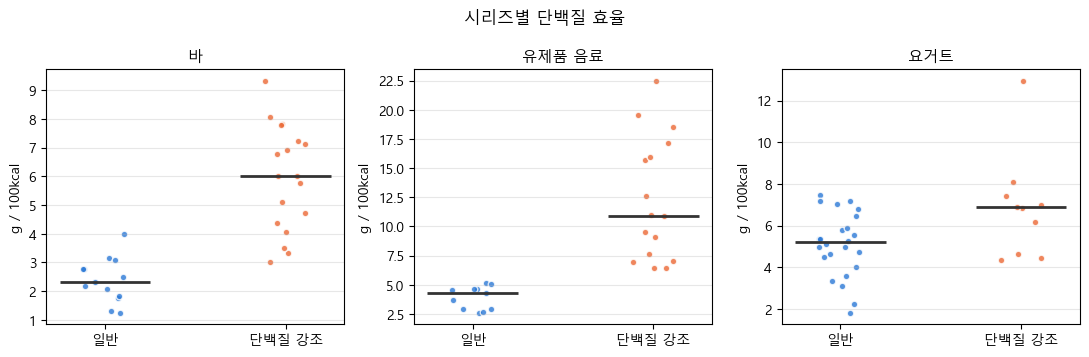

efficiency_mean  sugar_mean  sodium_mean  \
food_group protein_claim                                             
바          일반                        2.33       20.00        103.0   
           단백질 강조                    6.01       14.21        245.5   
유제품 음료     일반                        4.29        7.00         50.0   
           단백질 강조                   10.93        1.87         68.0   
요거트        일반                        5.19        8.45         47.5   
           단백질 강조                    6.87        7.00         73.0   

                          sat_fat_mean  energy_mean  
food_group protein_claim                             
바          일반                     5.00        485.0  
           단백질 강조                 5.75        415.5  
유제품 음료     일반                     2.26         68.0  
           단백질 강조                 0.28         56.5  
요거트        일반                     3.59        133.0  
           단백질 강조                 3.48        115.0

In [5]:
def strip(ax, data, column, title, unit):
    for i, claim in enumerate([0, 1]):
        values = data.loc[data["protein_claim"] == claim, column].dropna()
        jitter = np.random.default_rng(claim).uniform(-0.12, 0.12, len(values))
        ax.scatter(i + jitter, values, s=22, color=COLORS[claim], alpha=0.8, edgecolor="white")
        ax.hlines(values.median(), i - 0.25, i + 0.25, color="#333333", linewidth=2)
    ax.set_xticks([0, 1], [CLAIM[0], CLAIM[1]])
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(unit)
    ax.grid(axis="y", alpha=0.3)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (group, label) in zip(axes, GROUPS.items()):
    strip(ax, series[series["food_group"] == group], "efficiency_mean", label, "g / 100kcal")
fig.suptitle("시리즈별 단백질 효율", fontsize=12)
fig.tight_layout()
plt.show()

summary = series.groupby(["food_group", "protein_claim"])[
    ["efficiency_mean", "sugar_mean", "sodium_mean", "sat_fat_mean", "energy_mean"]].median()
display(summary.rename(index=GROUPS, level=0).rename(index=CLAIM, level=1))

중앙값 기준으로 강조 집단의 효율은 바 2.3 → 6.0, 음료 4.3 → 10.9, 요거트 5.2 → 6.9(g/100kcal)입니다. 음료에서 차이가 가장 크고 요거트에서 가장 작습니다. 식품군마다 차이의 크기가 달라 보인다는 점은 7장의 상호작용 검정을 하는 이유가 됩니다.

다른 성분에서는 몇 가지 패턴이 보입니다.

- **당류**는 세 식품군 모두 강조 집단이 낮습니다(음료 7.0 → 1.9g/100mL).
- **나트륨**은 바에서 강조 집단이 높습니다(103 → 246mg/100g).
- **포화지방**은 음료에서 두 집단이 거의 겹치지 않습니다(2.26 → 0.28g/100mL). 이 점은 머신러닝 결과를 이해하는 데 중요합니다.

### 보조 분석: 판정 없이 후보 전체를 함량으로 나누면?

판정 표본이 작다는 한계를 보완하려고, 판정 없이 후보 전체(자동 시리즈 2,316개)를 식약처 강조표시 기준으로 나눴습니다. 1일 기준치 55g 대비 바·요거트는 100g당 5.5g 이상이면 "급원", 11g 이상이면 "고", 음료는 100mL당 그 절반입니다. 100kcal당 기준은 효율과 같은 값이라 쓰지 않았습니다.

![법적 단백질 기준별 성분 분포](../shared/figures/pool_protein_levels.png)

In [6]:
spearman = pd.read_csv(RES / "pool_spearman.csv")
display(spearman.pivot(index="food_group", columns="metric", values="spearman_rho")
                .rename(index=GROUPS)[["당류", "나트륨", "포화지방", "열량"]].round(2))

legal = pd.read_csv(RES / "claim_vs_legal.csv")
legal = legal[legal["protein_claim"] == 1].set_index("food_group").rename(index=GROUPS)
legal["강조 제품 중 법적 '고' 충족"] = legal["legal_high_yes"].astype(str) + " / " + \
    (legal["legal_high_yes"] + legal["legal_high_no"]).astype(str)
display(legal[["강조 제품 중 법적 '고' 충족"]])

metric,당류,나트륨,포화지방,열량
food_group,,,,
바,-0.46,0.50,0.29,0.06
유제품 음료,-0.43,0.31,0.11,0.06
요거트,-0.41,-0.33,0.59,0.71


,강조 제품 중 법적 '고' 충족
food_group,
바,24 / 25
유제품 음료,21 / 24
요거트,0 / 14


단백질 함량과의 순위상관(Spearman)은 광고 기준 표본과 같은 방향입니다. 단백질이 많을수록 당류는 낮고, 요거트에서는 열량·포화지방이 높습니다. 판정 표본에서 본 패턴이 우연한 추출 결과만은 아닐 가능성을 보여 줍니다.

눈에 띄는 결과는 마지막 표입니다. **단백질을 강조한 요거트 14개 중 법적 "고" 기준(100g당 11g)을 넘은 제품은 하나도 없었습니다.** 법은 1회 섭취참고량 기준 등 다른 경로도 허용하므로 표시가 위법이라는 뜻은 아니지만, "고단백"이라는 인상과 실제 함량 사이의 간극을 보여 줍니다.

## 6. 가설검정: 강조 제품은 효율이 더 높은가?

시리즈 평균을 대상으로 식품군마다 강조 집단과 일반 집단을 양측 Welch t 검정으로 비교합니다. 두 집단의 분산이 같다고 가정하지 않는 검정입니다. 효율·당류·나트륨·포화지방·열량 5개 지표 × 3개 식품군 = 15개 검정의 p값을 Holm 방식으로 함께 보정합니다. 차이는 **강조 집단 평균에서 일반 집단 평균을 뺀 값**입니다. 시리즈를 집단별로 복원추출하는 부트스트랩 5,000회로도 차이의 구간을 구했습니다.

아래 코드는 이 계산을 처음부터 다시 하고, B의 결과 파일([`hypothesis_tests.csv`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/results/hypothesis_tests.csv))과 같은지 확인합니다.

In [7]:
METRICS = {"efficiency": "efficiency_mean", "sugar": "sugar_mean", "sodium": "sodium_mean",
           "sat_fat": "sat_fat_mean", "energy": "energy_mean"}
ORDER = ["bar", "yogurt", "dairy_drink"]          # B 분석과 같은 순서(난수 흐름도 같게)

def welch(high, regular, alpha=0.05):
    a, b = high.var(ddof=1) / len(high), regular.var(ddof=1) / len(regular)
    se, diff = np.sqrt(a + b), high.mean() - regular.mean()
    df = (a + b) ** 2 / (a ** 2 / (len(high) - 1) + b ** 2 / (len(regular) - 1))
    p = 2 * stats.t.sf(abs(diff / se), df)
    margin = stats.t.ppf(1 - alpha / 2, df) * se
    return diff, diff - margin, diff + margin, p

def bootstrap(high, regular, rng, n=5000):
    d = [rng.choice(high, len(high)).mean() - rng.choice(regular, len(regular)).mean() for _ in range(n)]
    return np.quantile(d, [0.025, 0.975])

rows = []
streams = iter(np.random.SeedSequence(42).spawn(len(ORDER) * len(METRICS)))
for group in ORDER:
    g = series[series["food_group"] == group]
    for metric, column in METRICS.items():
        high = g.loc[g["protein_claim"] == 1, column].dropna().to_numpy(float)
        regular = g.loc[g["protein_claim"] == 0, column].dropna().to_numpy(float)
        diff, lo, hi, p = welch(high, regular)
        b_lo, b_hi = bootstrap(high, regular, np.random.default_rng(next(streams)))
        rows.append(dict(food_group=group, metric=metric, n_regular=len(regular), n_high=len(high),
                         difference=diff, ci_low=lo, ci_high=hi, boot_low=b_lo, boot_high=b_hi, p_raw=p))
tests = pd.DataFrame(rows)
tests["p_holm"] = multipletests(tests["p_raw"], method="holm")[1]

saved = pd.read_csv(RES / "hypothesis_tests.csv", encoding="utf-8-sig")
assert np.allclose(tests["p_holm"], saved["p_holm"]) and np.allclose(tests["ci_low"], saved["ci_low"])
saved_boot = pd.read_csv(RES / "bootstrap_intervals.csv", encoding="utf-8-sig")
assert np.allclose(tests["boot_low"], saved_boot["ci_low"])
print("B의 결과 파일과 일치합니다.")

show = tests.assign(식품군=tests["food_group"].map(GROUPS),
                    **{"차이 (95% CI)": tests.apply(lambda r: f"{r.difference:+.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}]", axis=1),
                       "부트스트랩 95%": tests.apply(lambda r: f"[{r.boot_low:.2f}, {r.boot_high:.2f}]", axis=1),
                       "Holm p": tests["p_holm"].map(lambda p: f"{p:.2g}")})
display(show[["식품군", "metric", "n_regular", "n_high", "차이 (95% CI)", "부트스트랩 95%", "Holm p"]])

B의 결과 파일과 일치합니다.


,식품군,metric,n_regular,n_high,차이 (95% CI),부트스트랩 95%,Holm p
0,바,efficiency,13,18,"+3.56 [2.56, 4.55]","[2.66, 4.48]",1.7e-06
1,바,sugar,13,18,"-9.34 [-16.70, -1.98]","[-16.01, -2.66]",0.15
2,바,sodium,13,18,"+142.67 [43.08, 242.26]","[51.52, 234.24]",0.072
3,바,sat_fat,13,18,"-1.67 [-5.71, 2.36]","[-5.67, 1.36]",1
4,바,energy,13,18,"-36.82 [-108.85, 35.21]","[-96.33, 33.15]",1
5,요거트,efficiency,24,10,"+1.78 [-0.08, 3.63]","[0.33, 3.44]",0.53
6,요거트,sugar,24,10,"+0.36 [-4.00, 4.73]","[-3.33, 4.22]",1
7,요거트,sodium,24,10,"+15.10 [-6.70, 36.91]","[-3.52, 34.09]",0.96
8,요거트,sat_fat,24,10,"-0.61 [-2.41, 1.19]","[-2.27, 1.05]",1
9,요거트,energy,24,10,"-20.35 [-60.70, 20.00]","[-55.07, 18.13]",1


### 결과

| 식품군 | 일반 효율 | 강조 효율 | 효율 차이 (95% 신뢰구간) | Holm 보정 p |
|---|---:|---:|---:|---:|
| 바 | 2.39 | 5.94 | +3.56 [2.56, 4.55] | 0.0000017 |
| 유제품 음료 | 3.91 | 12.31 | +8.39 [5.55, 11.24] | 0.00013 |
| 요거트 | 5.10 | 6.87 | +1.78 [−0.08, 3.63] | 0.53 |

- **주가설**: 바와 유제품 음료에서는 강조 집단의 평균 효율이 분명히 높았습니다. 같은 100kcal로 바는 약 3.6g, 음료는 약 8.4g의 단백질을 더 줍니다.
- **요거트**는 일반 24개, 강조 10개 시리즈로 분석했습니다. 평균 차이는 양수였지만 Welch 신뢰구간에 0이 포함되었고, 보정 p도 0.05를 넘었습니다. 부트스트랩 구간 [0.33, 3.44]는 0을 포함하지 않아 두 방법의 결론이 엇갈립니다. 그래서 요거트의 효율 차이는 **불확실하다**고 해석합니다. 5장에서 본 것처럼 강조 요거트 중 법적 "고" 기준을 넘는 제품이 없었다는 점과도 맞는 결과입니다.
- **부가설**: 음료에서 강조 집단의 당류가 100mL당 4.71g, 포화지방이 1.53g 낮았고 보정 뒤에도 유의했습니다(p = 0.0034, 0.00000012). 그 밖의 부가설 검정은 보정 p < 0.05에 이르지 않았습니다. 바의 당류(−9.3g)와 나트륨처럼 보정 전에는 차이가 보이던 지표도, 15개를 함께 검정한 뒤에는 근거가 약해집니다.

## 7. 확장 가설: 효율 차이는 식품군마다 다른가?

식품군별로 "유의/비유의"를 나란히 놓는 것만으로는 차이의 크기가 다르다고 말할 수 없습니다. 그래서 효율을 강조 여부, 식품군, 둘의 상호작용으로 설명하는 회귀모형을 세우고 상호작용 항 2개가 모두 0인지 공동 Wald 검정을 했습니다. 집단마다 분산이 달라 이분산에 강한 HC3 표준오차를 썼습니다.

상호작용 공동 Wald 검정: chi2(2) = 16.06, p = 0.000326  (시리즈 92개)


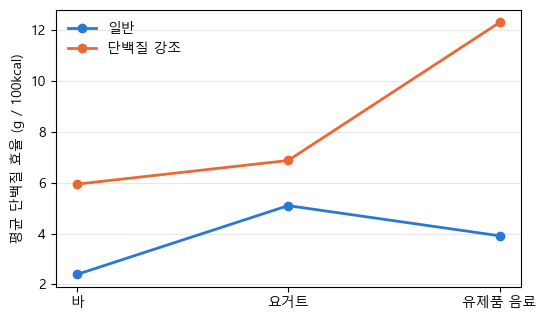

In [8]:
data = series.dropna(subset=["efficiency_mean"]).assign(
    food_group=lambda d: pd.Categorical(d["food_group"], categories=ORDER))
fit = smf.ols("efficiency_mean ~ protein_claim * C(food_group)", data=data).fit(cov_type="HC3")
interaction = [name for name in fit.params.index if ":" in name]
wald = fit.wald_test(np.eye(len(fit.params))[[list(fit.params.index).index(n) for n in interaction]],
                     use_f=False, scalar=True)
print(f"상호작용 공동 Wald 검정: chi2({len(interaction)}) = {float(wald.statistic):.2f}, "
      f"p = {float(wald.pvalue):.6f}  (시리즈 {int(fit.nobs)}개)")

means = data.groupby(["food_group", "protein_claim"], observed=True)["efficiency_mean"].mean().unstack()
fig, ax = plt.subplots(figsize=(6, 3.6))
for claim in [0, 1]:
    ax.plot([GROUPS[g] for g in ORDER], means.loc[ORDER, claim], marker="o",
            color=COLORS[claim], linewidth=2, label=CLAIM[claim])
ax.set_ylabel("평균 단백질 효율 (g / 100kcal)")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
plt.show()

χ²(2) = 16.06, p = 0.00033으로, 효율 차이의 크기는 식품군마다 달랐습니다. 그림에서 두 선의 간격이 음료에서 가장 넓고 요거트에서 가장 좁습니다. 이 분석은 사전에 탐색 분석으로 정했으므로 Holm 보정 묶음에 넣지 않았습니다.

## 8. 머신러닝: 단백질 수치 없이 강조 제품을 알아볼 수 있을까?

포장에서 단백질 숫자를 가렸다고 상상해 봅시다. 당류·나트륨·포화지방만 보고 이 시리즈가 단백질 강조 제품인지 맞힐 수 있을까요? 이 질문은 "강조 제품이 단백질 말고도 영양 구성이 체계적으로 다른가"를 묻는 것과 같습니다.

- **입력**: 시리즈의 당류·나트륨·포화지방 평균. 세 성분이 모두 있는 제품만으로 평균을 냈습니다([`series_ml.csv`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/data/processed/series_ml.csv)).
- **모델**: 가장 많은 집단을 항상 예측하는 기준 모델, 표준화 + 로지스틱 회귀, 최대 깊이 3 결정트리
- **평가**: 식품군별로 시리즈 단위 층화 5겹 교차검증(시드 42). 집단 크기가 달라 정확도 대신 **균형 정확도**와 강조 집단의 **F1 점수**를 씁니다.

같은 시리즈의 맛 제품은 이미 한 행으로 묶었으므로, 같은 라인이 학습과 평가에 동시에 들어가는 누수는 없습니다.

In [9]:
ml = pd.read_csv(PROC / "series_ml.csv", dtype={"series_id": str})
FEATURES = ["sugar_mean", "sodium_mean", "sat_fat_mean"]
MODELS = {
    "기준 모델": DummyClassifier(strategy="most_frequent"),
    "로지스틱 회귀": Pipeline([("scaler", StandardScaler()),
                          ("model", LogisticRegression(max_iter=3000, random_state=42))]),
    "결정트리": DecisionTreeClassifier(max_depth=3, random_state=42),
}

scores = []
for group in ORDER:
    g = ml[ml["food_group"] == group].sort_values("series_id").reset_index(drop=True)
    X, y = g[FEATURES], g["protein_claim"]
    splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))
    for name, estimator in MODELS.items():
        fold = []
        for train, test in splits:
            pred = clone(estimator).fit(X.iloc[train], y.iloc[train]).predict(X.iloc[test])
            fold.append([balanced_accuracy_score(y.iloc[test], pred),
                         f1_score(y.iloc[test], pred, pos_label=1, zero_division=0)])
        fold = np.array(fold)
        scores.append(dict(식품군=GROUPS[group], 모델=name, 시리즈=len(g),
                           균형정확도=fold[:, 0].mean(), 강조F1=fold[:, 1].mean()))
scores = pd.DataFrame(scores)
display(scores.pivot(index="모델", columns="식품군", values="균형정확도").round(2))

saved_ml = pd.read_csv(RES / "ml_summary.csv", encoding="utf-8-sig")
assert np.allclose(scores["균형정확도"], saved_ml["balanced_accuracy_mean"])
assert np.allclose(scores["강조F1"], saved_ml["f1_high_mean"])
print("B의 ml_summary.csv와 일치합니다.")

식품군,바,요거트,유제품 음료
모델,,,
결정트리,0.70,0.58,1.0
기준 모델,0.50,0.50,0.5
로지스틱 회귀,0.71,0.53,1.0


B의 ml_summary.csv와 일치합니다.


| 식품군 | 모델 | 균형 정확도 | 강조 집단 F1 |
|---|---|---:|---:|
| 바 | 다수 집단 기준 | 0.50 | 0.73 |
| 바 | 로지스틱 회귀 | 0.71 | 0.75 |
| 바 | 결정트리 | 0.70 | 0.65 |
| 유제품 음료 | 다수 집단 기준 | 0.50 | 0.74 |
| 유제품 음료 | 로지스틱 회귀 | 1.00 | 1.00 |
| 유제품 음료 | 결정트리 | 1.00 | 1.00 |
| 요거트 | 다수 집단 기준 | 0.50 | 0.00 |
| 요거트 | 로지스틱 회귀 | 0.53 | 0.10 |
| 요거트 | 결정트리 | 0.58 | 0.38 |

**음료의 균형 정확도 1.00은 이번 표본 27개 시리즈(일반 11, 강조 16)에서 나온 교차검증 결과입니다.** 두 모형이 다섯 겹의 모든 평가 시리즈를 맞혔지만, 이것이 "새 음료 제품도 완벽하게 구별한다"는 뜻은 아닙니다. 이 표본에서 100mL당 포화지방이 일반 1.48–2.60g, 강조 0.14–1.29g으로 두 집단이 완전히 떨어져 있었고, 결정트리는 다섯 겹 모두 포화지방으로 나눴습니다. 일반 우유와 저지방·탈지 원료를 쓰는 프로틴 음료의 차이를 모델이 그대로 잡은 것입니다. 표본이 작고 시리즈 하나가 평가 겹 하나의 20%를 차지하므로, 새 제품군에서의 성능은 별도 표본으로 검증해야 합니다.

바는 기준 모델보다 나았지만(0.71) 겹마다 편차가 컸습니다. 요거트는 강조 시리즈가 10개뿐이라 겹마다 강조 시리즈 2개로 평가했고, 균형 정확도와 F1이 모두 낮았습니다. 6장에서 본 것처럼 요거트는 두 집단의 영양 구성이 크게 다르지 않습니다.

<table><tr>
<td><img src="../shared/figures/b_ml_confusion_dairy_drink.png" width="320"><br>음료 혼동행렬 (평가 겹 예측 합계)</td>
<td><img src="../shared/figures/b_ml_tree_dairy_drink.png" width="420"><br>음료 결정트리 (전체 시리즈로 다시 적합)</td>
</tr></table>

바와 요거트의 혼동행렬·결정트리는 [`shared/figures`](https://github.com/kmy040306/kmy040306.github.io/tree/main/shared/figures)에 있습니다.

## 9. 사례 비교: 단백질 20g을 얻는 "비용"

마지막으로 효율이 높은 강조 제품을 일반적인 단백질 식품과 비교합니다. **같은 단백질 20g을 섭취하는 조건**으로 맞추면, 무엇을 얼마나 더 먹게 되는지 볼 수 있습니다.

- 함께 먹는 성분 = 성분 ÷ 단백질 × 20
- 필요한 양 = 기준량 ÷ 단백질 × 20

비교 식품은 삶은 닭가슴살과 삶은 달걀([농촌진흥청 국가표준식품성분표](https://koreanfood.rda.go.kr/)), 두부(주자료의 농촌진흥청 행)입니다. 강조 제품은 식품군별로 효율 상위 25% 시리즈를 골랐고, 제품별 값 → 시리즈 평균 → 집단 평균 순서로 계산했습니다.

,필요량,열량(kcal),당류(g),나트륨(mg),포화지방(g)
바 상위 25% (5개),69.1,250.2,4.1,226.1,4.2
요거트 상위 25% (3개),277.6,226.3,13.3,182.7,4.2
유제품 음료 상위 25% (4개),195.5,104.1,1.3,135.6,0.4
닭가슴살,71.2,90.4,0.0,28.5,0.3
달걀,148.3,215.0,0.2,189.8,4.1
두부,207.9,201.7,0.0,2.1,1.5


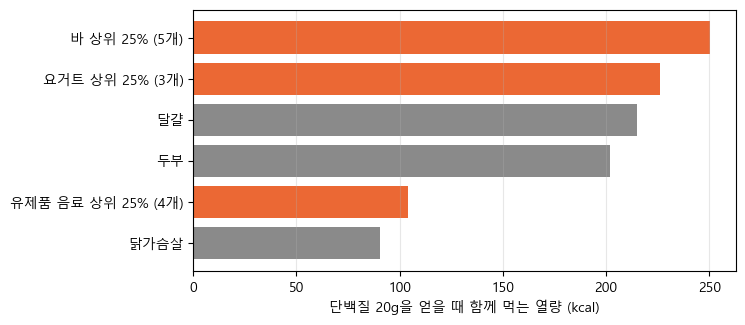

In [10]:
PER = {"energy_kcal": "열량(kcal)", "sugar_g": "당류(g)", "sodium_mg": "나트륨(mg)", "sat_fat_g": "포화지방(g)"}

def per_20g(frame):
    out = pd.DataFrame({label: frame[col] / frame["protein_g"] * 20 for col, label in PER.items()})
    out["필요량"] = frame["basis_amount"] / frame["protein_g"] * 20
    return out

high = products[products["protein_claim"] == 1]
rows = {}
for group in ORDER:
    g = high[high["food_group"] == group]
    by_series = per_20g(g).groupby(g["series_id"]).mean()
    eff = g.groupby("series_id")["protein_efficiency"].mean()
    top = eff[eff >= eff.quantile(0.75)].index
    rows[f"{GROUPS[group]} 상위 25% ({len(top)}개)"] = by_series.loc[top].mean()

ref = pd.read_csv(PROC / "reference_foods.csv")
for _, r in ref.iterrows():
    rows[r["food_name"]] = per_20g(r.to_frame().T.astype({c: float for c in [*PER, "protein_g", "basis_amount"]})).iloc[0]
comparison = pd.DataFrame(rows).T[["필요량", *PER.values()]]
display(comparison.round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
order = comparison["열량(kcal)"].sort_values()
ax.barh(order.index, order.values, color=["#eb6834" if "상위" in i else "#8a8a8a" for i in order.index])
ax.set_xlabel("단백질 20g을 얻을 때 함께 먹는 열량 (kcal)")
ax.grid(axis="x", alpha=0.3)
plt.show()

- **효율 상위 음료**(약 196mL)는 열량·포화지방이 닭가슴살과 비슷하고 당류도 1g 남짓입니다. 나트륨은 닭가슴살보다 높습니다.
- **효율 상위 바**는 양이 가장 적게 들지만(약 69g), 같은 단백질에 열량이 닭가슴살의 약 2.8배이고 나트륨이 200mg 넘게 따라옵니다.
- **효율 상위 요거트**는 300g 가까이 먹어야 하고, 당류가 13g 정도 따라옵니다.

두 가지를 주의해야 합니다. 첫째, **단백질 20g당 열량은 효율의 역수(2000 ÷ 효율)** 이므로 효율 결과와 독립된 새 발견이 아닙니다. 둘째, 상위 25%는 같은 데이터에서 효율로 고른 집단이어서 "고단백 제품이 닭가슴살만큼 좋다"는 일반화가 아니라 **탐색적 사례**입니다. 조리 방식(삶음)과 가공식품(그대로 섭취)의 차이도 있습니다.

## 10. 결론

| 질문 | 답 |
|---|---|
| 강조 제품은 같은 열량으로 단백질을 더 주는가? | **바와 음료는 그렇다.** 100kcal당 바 +3.6g, 음료 +8.4g. 요거트는 차이가 불확실하다(+1.8g, 신뢰구간이 0을 포함). |
| 다른 성분은 어떻게 다른가? | 음료 강조 제품은 당류·포화지방이 낮았다. 나머지 차이는 다중검정 보정 뒤 근거가 약하다. |
| 차이는 식품군마다 다른가? | 그렇다. 음료에서 가장 크고 요거트에서 가장 작다(상호작용 p = 0.00033). |
| 영양 성분만으로 강조 제품을 알아볼 수 있는가? | 음료는 이번 27개 시리즈에서 포화지방만으로 완전히 구분되었다. 바는 중간, 요거트는 거의 구분되지 않았다. |

실용적으로 정리하면, **"프로틴" 음료는 이름값을 하는 편이고, "고단백" 요거트는 표시만 보고 일반 요거트보다 단백질이 훨씬 많다고 기대하기 어렵습니다.** 강조 요거트 14개 중 법적 "고" 기준(100g당 11g)을 넘은 제품은 없었습니다. 바는 단백질 효율이 높지만 나트륨과 열량을 함께 보는 것이 좋습니다.

## 11. 한계

- 데이터베이스에 수록되어 있고 포장을 확인할 수 있었던 제품만 분석했습니다. 보류 127행은 분석에서 빠졌고, 표본은 시장 전체를 대표하지 않습니다.
- 요거트 강조 집단은 10개 시리즈로 추론 기준선에 있습니다. 시리즈 몇 개의 판정이 바뀌면 결론이 달라질 수 있습니다.
- 영양 데이터베이스의 배합과 현재 판매 제품의 배합이 다를 수 있습니다.
- 같은 브랜드의 시리즈끼리도 완전히 독립은 아닙니다.
- 법적 강조표시 기준 수치는 식약처 가이드라인을 보조 출처로 확인했으며, 1회 섭취참고량 기준은 적용하지 않았습니다.

## 재현 방법과 자료

```bash
python A_data_eda/code/02_clean.py         # 판정표 + 원자료 → 제품 표 (원자료 필요)
python A_data_eda/code/03_build_metrics.py # 제품 표 → 시리즈 표
python B_statistics_ml/code/01_tests.py    # Welch·Holm·부트스트랩
python B_statistics_ml/code/02_interaction.py
python B_statistics_ml/code/03_ml.py
```

이 노트북은 저장소의 가공 데이터만으로 실행됩니다. 원자료가 필요한 단계는 [`handoff_v001.md`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/docs/handoff_v001.md)에 파일 해시와 함께 정리했습니다.

- 선정 규칙: [`selection_rules.md`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/docs/selection_rules.md) · 판정 가이드: [`review_guide.md`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/docs/review_guide.md) · 결정 기록: [`decisions.md`](https://github.com/kmy040306/kmy040306.github.io/blob/main/shared/docs/decisions.md)
- 수집·정제·EDA 코드: [`A_data_eda/code`](https://github.com/kmy040306/kmy040306.github.io/tree/main/A_data_eda/code) · 통계·ML 코드: [`B_statistics_ml/code`](https://github.com/kmy040306/kmy040306.github.io/tree/main/B_statistics_ml/code)
- 더 읽을거리: [식약처 한눈에 보는 영양표시 가이드라인](https://www.mfds.go.kr/brd/m_1060/view.do?seq=15805) · [scikit-learn 교차검증 안내](https://scikit-learn.org/stable/modules/cross_validation.html) · [statsmodels 강건 표준오차(HC3)](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html)